# Imports

In [1]:
import os

os.environ["KERAS_BACKEND"] = "torch"
import keras
import torch

In [2]:
import datasets
import numpy as np
import pandas as pd
import sklearn.metrics
import tqdm.notebook as tqdm
import sklearn.model_selection
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, Qwen2TokenizerFast
import seaborn as sns

c:\Users\Yanovich\Documents\Projects\Cats\neural\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Tokenizer

Train your own tokenizer on an English corpus or load a pretrained tokenizer for English sentences (see the one used in class)

In [3]:
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

# Dataset

Load the dataset (we will be using [imdb](https://huggingface.co/datasets/stanfordnlp/imdb)). Pretokenize data or make a loader that tokenizes the sentenses as you iterate through the dataset.

In [4]:
train_dataset: datasets.Dataset = datasets.load_dataset('stanfordnlp/imdb', split='train')
test_dataset: datasets.Dataset = datasets.load_dataset('stanfordnlp/imdb', split='test')

In [5]:
train_df: pd.DataFrame = train_dataset.to_pandas()
test_df: pd.DataFrame = test_dataset.to_pandas()

In [6]:
train_df

,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0
...,...,...
24995,A hit at the time but now better categorised a...,1
24996,I love this movie like no other. Another time ...,1
24997,This film and it's sequel Barry Mckenzie holds...,1
24998,'The Adventures Of Barry McKenzie' started lif...,1


In [7]:
test_df

,text,label
0,I love sci-fi and am willing to put up with a ...,0
1,"Worth the entertainment value of a rental, esp...",0
2,its a totally average film with a few semi-alr...,0
3,STAR RATING: ***** Saturday Night **** Friday ...,0
4,"First off let me say, If you haven't enjoyed a...",0
...,...,...
24995,Just got around to seeing Monster Man yesterda...,1
24996,I got this as part of a competition prize. I w...,1
24997,I got Monster Man in a box set of three films ...,1
24998,"Five minutes in, i started to feel how naff th...",1


In [8]:
train_df["label"].value_counts()

label
0    12500
1    12500
Name: count, dtype: int64

In [9]:
test_df["label"].value_counts()

label
0    12500
1    12500
Name: count, dtype: int64

In [10]:
train_tokens: list[list[int]] = tokenizer(list(train_dataset["text"]))["input_ids"]
test_tokens: list[list[int]] = tokenizer(list(test_dataset["text"]))["input_ids"]

Token indices sequence length is longer than the specified maximum sequence length for this model (720 > 512). Running this sequence through the model will result in indexing errors


In [11]:
train_tokens_len = [len(tokens) for tokens in train_tokens]
test_tokens_len = [len(tokens) for tokens in test_tokens]

<Axes: ylabel='Count'>

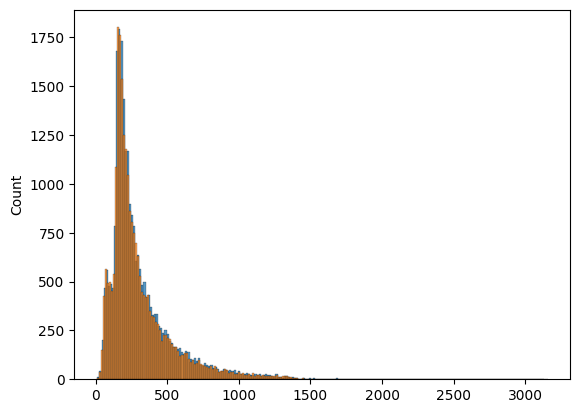

In [12]:
sns.histplot(train_tokens_len)
sns.histplot(test_tokens_len, alpha=0.7)

In [13]:
np.quantile(train_tokens_len, 0.99), np.quantile(test_tokens_len, 0.99)

(np.float64(1206.0), np.float64(1192.0099999999984))

In [14]:
np.quantile(train_tokens_len, 0.95), np.quantile(test_tokens_len, 0.95)

(np.float64(806.0499999999993), np.float64(784.0499999999993))

In [15]:
class SequenceDataset(keras.utils.PyDataset):
    def __init__(
        self,
        x,
        y,
        tokenizer,
        max_seq_length: int,
        fixed_seq_length: bool,
        batch_size: int = 128,
        shuffle: bool = True,
        rng: np.random.Generator | None = None,
        **kwargs,
    ):
        super().__init__(**kwargs)
        if rng is None:
            rng = np.random.default_rng()

        self.rng = rng
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.max_seq_length = max_seq_length
        self.fixed_seq_length = fixed_seq_length
        self.tokenizer = tokenizer

        self.raw_text_tokens = [seq[:max_seq_length] for seq in x]
        self.y = np.array(y)

        if fixed_seq_length:
            self.padded_text_tokens = self.pad_sequences(
                self.raw_text_tokens, maxlen=max_seq_length
            )

        self.batch_order: list[np.ndarray] = []
        self.on_epoch_end()

    @classmethod
    def pad_sequences(cls, x, maxlen) -> np.ndarray:
        return keras.utils.pad_sequences(
            x,
            maxlen=maxlen,
            padding="post",
            truncating="post",
            value=tokenizer.pad_token_id,
        )

    def __len__(self):
        return len(self.batch_order)

    def __getitem__(self, idx):
        batch_indices = self.batch_order[idx]

        if not self.fixed_seq_length:
            text_tokens = [self.raw_text_tokens[i] for i in batch_indices]
            max_len = max(len(tokens) for tokens in text_tokens)
            x = self.pad_sequences(text_tokens, maxlen=max_len)
        else:
            x = self.padded_text_tokens[batch_indices]

        return x, self.y[batch_indices]

    def on_epoch_end(self):
        n = len(self.raw_text_tokens)
        if n == 0:
            self.batch_order = []
            return

        boundaries = list(range(0, n, self.batch_size)) + [n]

        if self.fixed_seq_length:
            if self.shuffle:
                indices = self.rng.permutation(n)
            else:
                indices = np.arange(n)
        else:
            lengths = np.array([len(t) for t in self.raw_text_tokens])
            if self.shuffle:
                jitter = self.rng.random(n)
                indices = np.lexsort((jitter, lengths))
            else:
                indices = np.argsort(lengths, kind="stable")

        batches = [
            indices[boundaries[i] : boundaries[i + 1]]
            for i in range(len(boundaries) - 1)
        ]

        if self.shuffle and not self.fixed_seq_length:
            self.rng.shuffle(batches)

        self.batch_order = batches

In [27]:
train_ds = SequenceDataset(
    train_tokens,
    list(train_dataset["label"]),
    tokenizer,
    max_seq_length=256,
    fixed_seq_length=False,
    batch_size=32,
)

In [28]:
test_ds = SequenceDataset(
    test_tokens,
    list(test_dataset["label"]),
    tokenizer,
    max_seq_length=256,
    fixed_seq_length=False,
    batch_size=32,
    shuffle=False
)

In [29]:
batches_positive_counts = [(tokens.shape[-1], sum(labels)) for tokens, labels in train_ds]
x_vals, y_vals = zip(*batches_positive_counts)

<Axes: >

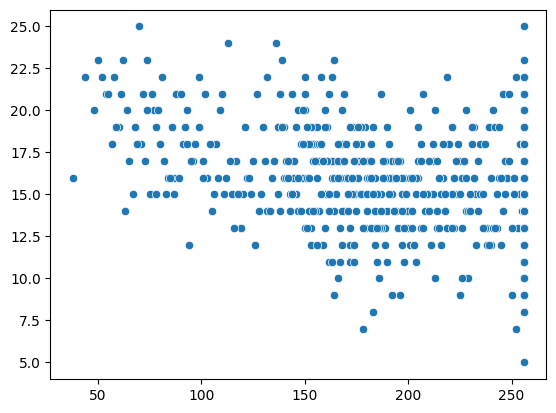

In [30]:
sns.scatterplot(x=x_vals, y=y_vals)

In [31]:
np.corrcoef(x_vals, y_vals)

array([[ 1.       , -0.2163383],
       [-0.2163383,  1.       ]])

# Model

Implement your model. The model should have the Transformer architecture. Remember to mask out padding tokens.

In [32]:
class TokenAndPositionEmbedding(keras.layers.Layer):
    def __init__(self, maxlen, vocab_size, embed_dim, **kwargs):
        super().__init__(**kwargs)
        self.maxlen = maxlen
        self.token_emb = keras.layers.Embedding(
            vocab_size, embed_dim, mask_zero=True
        )
        self.pos_emb = keras.layers.Embedding(maxlen, embed_dim)
        self.cls_token = self.add_weight(
            shape=(1, 1, embed_dim),
            initializer="random_normal",
            trainable=True,
            name="cls_token",
        )

    def call(self, x):
        seq_len = keras.ops.shape(x)[1]
        positions = keras.ops.arange(seq_len, dtype="int32")
        positions = keras.ops.expand_dims(positions, 0)

        x_emb = self.token_emb(x) + self.pos_emb(positions)

        batch_size = keras.ops.shape(x)[0]
        cls_tokens = keras.ops.broadcast_to(
            self.cls_token, (batch_size, 1, x_emb.shape[-1])
        )
        x_emb = keras.ops.concatenate([cls_tokens, x_emb], axis=1)
        return x_emb

In [33]:
def transformer_block(x, embedding_size, num_heads, block_features, dropout):
    h = keras.layers.LayerNormalization(epsilon=1e-6)(x)
    h = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embedding_size // num_heads,
        dropout=dropout,
    )(h, h)
    h = keras.layers.Dropout(dropout)(h)
    x = keras.layers.Add()([x, h])

    h = keras.layers.LayerNormalization(epsilon=1e-6)(x)
    h = keras.layers.Dense(block_features, activation="gelu")(h)
    h = keras.layers.Dense(embedding_size)(h)
    h = keras.layers.Dropout(dropout)(h)
    x = keras.layers.Add()([x, h])
    return x

In [34]:
def get_model(
    vocab_size: int,
    embedding_size: int,
    max_length: int,
    num_blocks: int,
    num_heads: int,
    name: str | None = None
) -> keras.Model:
    '''Creates a model with Transformer architecture for binary sequence classification.

    Arguments:
        vocab_size: size of the tokenizer vocabulary
        embedding_size: size of the internal mdoel representations 
        max_length: maximal allowed sequence length
        num_blocks: number of transformer blocks
        num_heads: number of multi head attentions heads
        pad_token_id: id of the padding token
        name: the model name

    Returns:
        The model'''
    tokens = keras.layers.Input(shape=(None,), dtype="int32", name="tokens")

    x = TokenAndPositionEmbedding(max_length, vocab_size, embedding_size)(tokens)
    x = keras.layers.Dropout(0.3)(x)

    for _ in range(num_blocks):
        x = transformer_block(x, embedding_size, num_heads, 256, 0.3)

    x = keras.layers.LayerNormalization(epsilon=1e-6)(x)
    x = keras.layers.Lambda(lambda t: t[:, 0, :])(x) 
    x = keras.layers.Dense(128, activation="gelu")(x)
    x = keras.layers.Dropout(0.3)(x)
    out = keras.layers.Dense(1, activation="sigmoid")(x)

    return keras.Model(tokens, out, name=name)

# Training

Train the model. Choose model size, batch size, loss, learning rate schedule.

In [35]:
model = get_model(
    vocab_size=tokenizer.vocab_size,
    embedding_size=128,
    max_length=train_ds.max_seq_length,
    num_blocks=4,
    num_heads=4,
    name="transformer"
)

In [36]:
model.compile(
    optimizer=keras.optimizers.AdamW(5e-5),
    loss="binary_crossentropy",
    metrics=["accuracy", "auc"],
)

In [37]:
model.fit(train_ds, validation_data=test_ds, epochs=10)

Epoch 1/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 178s 227ms/step - accuracy: 0.6080 - auc: 0.6727 - loss: 0.6357 - val_accuracy: 0.8104 - val_auc: 0.8962 - val_loss: 0.4481
Epoch 2/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 182s 232ms/step - accuracy: 0.8453 - auc: 0.9161 - loss: 0.3679 - val_accuracy: 0.8478 - val_auc: 0.9266 - val_loss: 0.3632
Epoch 3/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 175s 224ms/step - accuracy: 0.8839 - auc: 0.9482 - loss: 0.2895 - val_accuracy: 0.8532 - val_auc: 0.9307 - val_loss: 0.3649
Epoch 4/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 178s 228ms/step - accuracy: 0.9010 - auc: 0.9624 - loss: 0.2468 - val_accuracy: 0.8433 - val_auc: 0.9305 - val_loss: 0.3994
Epoch 5/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 181s 231ms/step - accuracy: 0.9196 - auc: 0.9721 - loss: 0.2112 - val_accuracy: 0.8512 - val_auc: 0.9269 - val_loss: 0.4610
Epoch 6/10
782/782 ━━━━━━━━━━━━━━━━━━━━ 176s 226ms/step - accuracy: 0.9286 - auc: 0.9773 - loss: 0.1879 - val_accuracy: 0.8380 - val_auc: 0.9229 - val_loss: 0.5104
Epoch 7/10
782/7

# Evaluation

Evaluate the model you trained on the test dataset. Plot the ROC curve.

Inspect the best model performance closer. Come up with some sentences (in English). Does the model output sensible results?

In [ ]:
def label_text(text: str, model: keras.Model, threshold: float = 0.5, max_length: int | None = None) -> int:
    '''Computes the model output for `text` and outputs the predicted label

    Arguments:
        text: text to label
        model: model to use
        threshold: threshold to use
        max_length: max length for tokenization
    
    Return:
        Predicted label'''

# Bonus

Inspect the model attention scores with respect to words and punctuation in the sentence. What does the model consider when classifying the sentence.